# 05_04 The Bootstrap and Monte Carlo: Let the Computer Do the Sampling

**Learning objectives**
- Understand the **plug-in principle**: the sample is our best picture of the population, so *resampling the sample* imitates *resampling the population*.
- Compute a **bootstrap standard error** and **confidence interval** for statistics with no formula (median, percentiles, ratios), and know the variants (percentile, basic, BCa).
- Use **Monte Carlo** simulation from a *known* model to estimate probabilities and expectations, and choose the **number of simulations** from its own standard error.
- Recognise when the bootstrap **fails** (extremes, tiny samples, heavy tails, dependent data) and check it by coverage simulation.

**Prerequisites:** [05_01 Law of large numbers](05_01_law_of_large_numbers.ipynb), [05_03 Sampling distributions and standard error](05_03_sampling_distributions_standard_error.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Sampling distribution** of a statistic: its distribution over repeated samples from the *population*; its standard deviation is the **standard error** (05_03).
- **Empirical distribution function (ECDF):** $\hat F_n(x)=\frac1n\#\{i:X_i\le x\}$ puts mass $1/n$ on each observation. By the law of large numbers (05_01) $\hat F_n\to F$.
- **Percentile:** the $q$-quantile of a list of numbers; **np.percentile** computes it.
- **Standard error of a simulation estimate:** the average of $B$ iid draws has SE $\sigma/\sqrt B$ (05_01).

## 3. Intuition and story

For the mean we have a formula for the standard error, $s/\sqrt n$. But what is the standard error of the **median** delivery time, or of the **90th percentile**, or of a **ratio of two rates**? There is often no clean formula. In 05_03 the way to learn the sampling distribution was to *draw many new samples from the population*. We cannot do that in real life: we have **one** sample.

**The bootstrap's idea (Efron, 1979).** Treat the sample as if it were the population, and draw new "samples" **from it, with replacement**, each the same size as the original. Compute the statistic on each resample. The spread of those values estimates the sampling distribution. It costs nothing but computer time.

**Monte Carlo** is the sibling idea: when you *know* the model (distributions of the parts) but cannot compute the answer analytically, simulate the model many times and average. The bootstrap is Monte Carlo applied to the *empirical* distribution.

## 4. Formal definition

**Nonparametric bootstrap.** Given data $x_1,\dots,x_n$ and a statistic $T$:
1. For $b=1,\dots,B$: draw $x^*_1,\dots,x^*_n$ **with replacement** from $\{x_1,\dots,x_n\}$ and compute $T^*_b=T(x^*)$.
2. **Bootstrap SE:** $\widehat{\mathrm{SE}}_{\rm boot}=\sqrt{\frac1{B-1}\sum_b(T^*_b-\bar T^*)^2}$. **Bootstrap bias:** $\bar T^*-T(x)$.
3. **Confidence intervals** (level $1-\alpha$, $T^*_{(q)}$ is the $q$-quantile of the $T^*_b$):

| Method | Interval | Notes |
|---|---|---|
| Normal | $T\pm z_{1-\alpha/2}\,\widehat{\mathrm{SE}}_{\rm boot}$ | needs near-Normal $T$ |
| Percentile | $\big[T^*_{(\alpha/2)},\,T^*_{(1-\alpha/2)}\big]$ | simplest, popular |
| Basic (pivotal) | $\big[2T-T^*_{(1-\alpha/2)},\,2T-T^*_{(\alpha/2)}\big]$ | corrects for bias in $T$ |
| BCa | percentile with bias and acceleration adjustments | best all-round (scipy) |

**Parametric bootstrap.** Fit a model $\hat\theta$ and draw resamples from the *fitted model* instead of from the data.

**Monte Carlo estimate** of $\theta=E[g(X)]$ from a known model: $\hat\theta_B=\frac1B\sum g(X_b)$ with $\mathrm{SE}=\sigma_g/\sqrt B$; for a probability $p$, $\mathrm{SE}=\sqrt{p(1-p)/B}$.

## 5. Derivations

### 5.1 Why resampling works (the plug-in principle)
The statistic $T$ depends on the sample, whose distribution depends on the unknown $F$. Replace $F$ by $\hat F_n$ (which converges to $F$): the *bootstrap world* "$\hat F_n\to$ resample $\to T^*$" imitates the *real world* "$F\to$ sample $\to T$". The relationships carry over: the spread of $T^*$ around $T$ estimates the spread of $T$ around the truth. **In plain words.** We cannot go back to the population, but the sample is a miniature of it, so sampling the miniature shows how much a sample of this size jumps around.

### 5.2 For the mean the bootstrap can be done exactly
Under $\hat F_n$ each $X^*_i$ has mean $\bar x$ and variance $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$ (divide by $n$, because that is the variance of the empirical distribution). So $\mathrm{Var}(\bar X^*)=\hat\sigma^2/n$ and the (ideal, $B=\infty$) bootstrap SE is $\sqrt{\tfrac{n-1}{n}}\;s/\sqrt n$: almost the usual formula, smaller by the factor $\sqrt{(n-1)/n}$. We verify this in 9.1. The bootstrap is only *needed* for statistics where no such formula exists.

### 5.3 How many resamples? (the Monte Carlo error)
The bootstrap has two sources of error: **(i)** the sample itself (cannot be removed: this is what the SE estimates) and **(ii)** the finite number $B$ of resamples (can be made small). For the SE, $B=200$ already gives a relative error of about $1/\sqrt{2B}=5\,\%$; for percentile limits, which live in the tails, use $B\ge2{,}000$ to $10{,}000$. For a simulated probability $\hat p$, the standard error is $\sqrt{p(1-p)/B}$: to get a probability near 0.03 to within $\pm0.001$ with 95 % confidence you need $B\approx(1.96)^2\cdot0.03\cdot0.97/0.001^2\approx112{,}000$.

### 5.4 Why the percentile interval can be wrong
The percentile interval uses the resample distribution of $T^*$ *around $T$* as if it were the distribution of $T$ around $\theta$. If $T$ is **biased** or **skewed**, those two differ; the **basic** interval flips the quantiles to correct for bias, and **BCa** corrects for both bias and skew-induced change of SE (the *acceleration*).

### 5.5 When the bootstrap fails
- **Extremes** (sample maximum or minimum): the resample maximum equals the sample maximum with probability $1-(1-1/n)^n\to63\,\%$, so $T^*$ has a spike that the real sampling distribution does not (7.6).
- **Tiny samples** ($n\lesssim15$): the sample is a poor miniature of the population, particularly in the tails.
- **Heavy tails** with infinite variance: the bootstrap of the mean is inconsistent.
- **Dependent data** (time series, clusters): resample **blocks** or clusters, not single observations.

## 6. Properties and relationships

- **Resampling with replacement** is essential: without replacement a resample of size $n$ is just the original sample re-ordered.
- **Each resample contains about 63.2 % of the distinct original points** ($1-e^{-1}$); the others are left out ("out-of-bag"), which is used in bagging and random forests (Module 09).
- **The bootstrap SE of the mean** is almost the textbook SE; the bootstrap is valuable for **medians, percentiles, ratios, correlations, regression coefficients** and any complicated statistic.
- **Permutation tests** also resample, but *without replacement and under the null hypothesis* (shuffle group labels); the bootstrap makes confidence intervals, the permutation test makes p-values (Example 2).
- **Monte Carlo versus bootstrap:** Monte Carlo samples from a *specified* distribution; the bootstrap samples from the *empirical* distribution of the data.
- **Link to Module 12:** Monte Carlo is the engine of all sampling algorithms; its error rate $1/\sqrt B$ is the LLN's (05_01).

## 7. 2D visuals

### 7.1 The sample as a miniature of the population
True population CDF (delivery times, as in 05_03) with the empirical CDF of one sample of size $n=30$ and of size $n=300$. The staircase is the 'population' the bootstrap draws from; it tracks the truth better as $n$ grows.

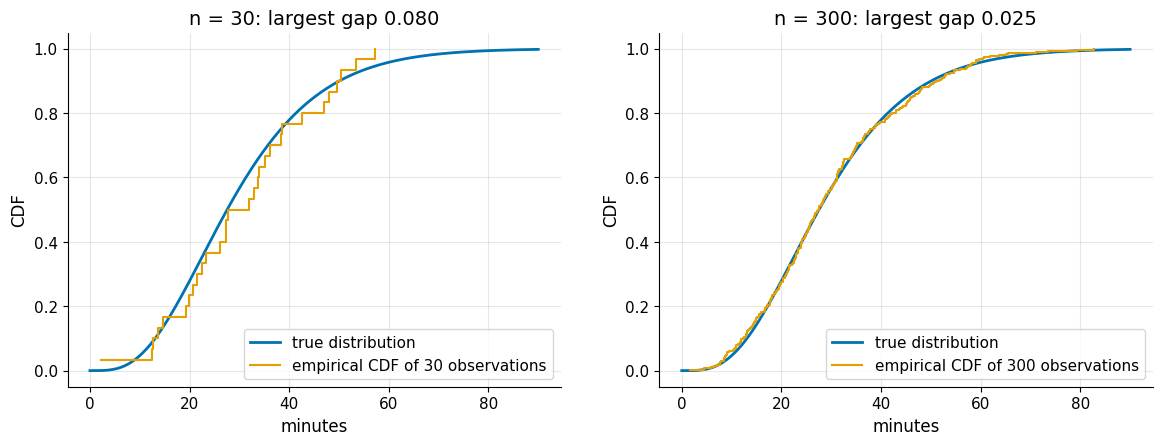

In [2]:
pop_rng = np.random.default_rng(2025)
population = pop_rng.gamma(shape=4, scale=7.5, size=20_000)
N = population.size
true_cdf = stats.gamma(a=4, scale=7.5).cdf
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.linspace(0, 90, 500)
for ax, n in zip(axes, [30, 300]):
    sample = np.sort(rng.choice(population, n, replace=False))
    ax.plot(x, true_cdf(x), color=MAIN, linewidth=2, label="true distribution")
    ax.step(sample, np.arange(1, n + 1) / n, where="post", color=SIM, linewidth=1.5, label=f"empirical CDF of {n} observations")
    ax.set_title(f"n = {n}: largest gap {np.max(np.abs(np.arange(1, n + 1) / n - true_cdf(sample))):.3f}")
    ax.set_xlabel("minutes"); ax.set_ylabel("CDF"); ax.legend()
plt.show()

### 7.2 One bootstrap, step by step
A sample of 60 delivery times (mean about 30, skewed). Ten resamples of the *same size, with replacement*: each has a different mean and median. The bootstrap distribution of the mean (right) is built from 10,000 such resamples.

sample: n = 60, mean 31.76, median 30.45, sd 13.92


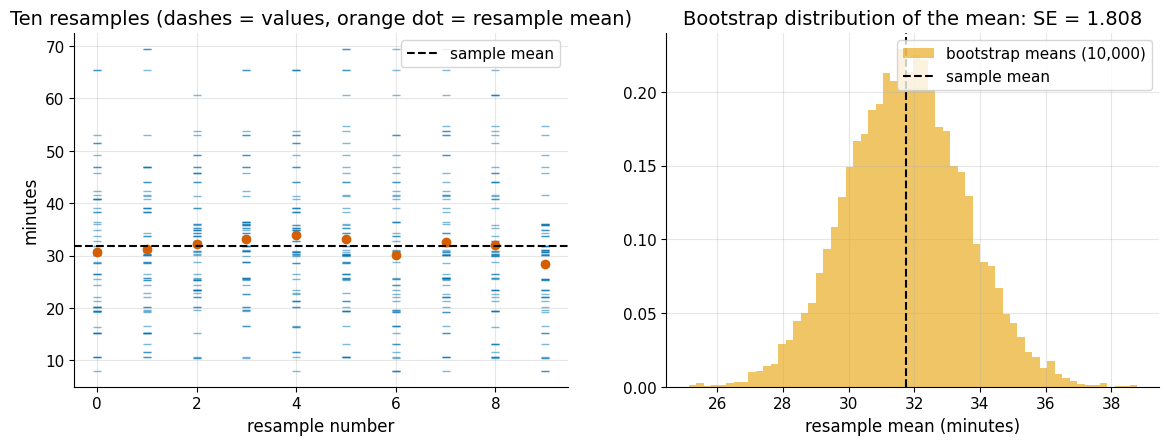

In [3]:
sample_rng = np.random.default_rng(5)
sample = population[sample_rng.choice(N, 60, replace=False)]
n = sample.size
print(f"sample: n = {n}, mean {sample.mean():.2f}, median {np.median(sample):.2f}, sd {sample.std(ddof=1):.2f}")
B = 10_000
boot_idx = rng.integers(0, n, (B, n))                       # B x n matrix of row indices: each row is one resample
boot_means = sample[boot_idx].mean(axis=1)
boot_medians = np.median(sample[boot_idx], axis=1)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.6))
for i in range(10):
    ax_a.plot(np.full(n, i), np.sort(sample[boot_idx[i]]), "_", color=MAIN, alpha=0.5)
    ax_a.plot(i, sample[boot_idx[i]].mean(), "o", color=HIGHLIGHT)
ax_a.axhline(sample.mean(), color="black", linestyle="--", label="sample mean")
ax_a.set_title("Ten resamples (dashes = values, orange dot = resample mean)")
ax_a.set_xlabel("resample number"); ax_a.set_ylabel("minutes"); ax_a.legend()
ax_b.hist(boot_means, bins=60, density=True, color=SIM, alpha=0.6, label="bootstrap means (10,000)")
ax_b.axvline(sample.mean(), color="black", linestyle="--", label="sample mean")
ax_b.set_title(f"Bootstrap distribution of the mean: SE = {boot_means.std(ddof=1):.3f}")
ax_b.set_xlabel("resample mean (minutes)"); ax_b.legend()
plt.show()

### 7.3 The bootstrap imitates the true sampling distribution
The real sampling distribution of the mean (from 20,000 fresh samples of the population) next to the bootstrap distribution built from one sample. They have the same shape and spread; the only difference is the centre (the bootstrap is centred on the sample mean, the truth on $\mu$).

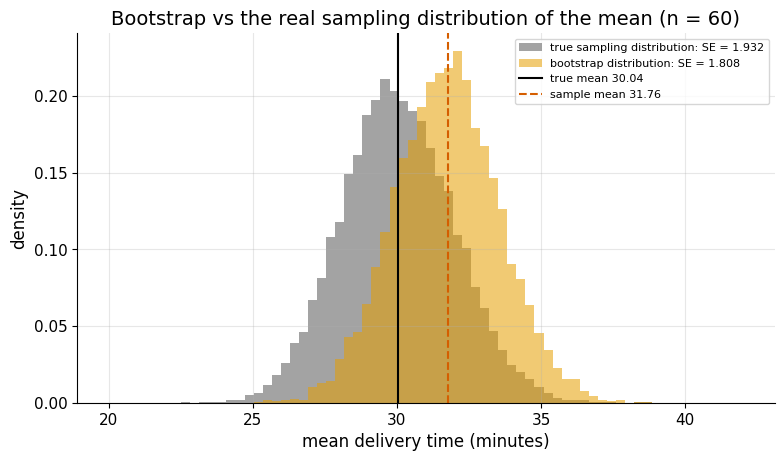

In [4]:
true_means = np.array([population[rng.choice(N, n, replace=False)].mean() for _ in range(20_000)])
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(true_means, bins=70, density=True, range=(20, 42), color=NEUTRAL, alpha=0.6, label=f"true sampling distribution: SE = {true_means.std():.3f}")
ax.hist(boot_means, bins=70, density=True, range=(20, 42), color=SIM, alpha=0.55, label=f"bootstrap distribution: SE = {boot_means.std():.3f}")
ax.axvline(population.mean(), color="black", label=f"true mean {population.mean():.2f}")
ax.axvline(sample.mean(), color=HIGHLIGHT, linestyle="--", label=f"sample mean {sample.mean():.2f}")
ax.set_title("Bootstrap vs the real sampling distribution of the mean (n = 60)")
ax.set_xlabel("mean delivery time (minutes)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.show()

### 7.4 The median has no formula: the bootstrap does it
Bootstrap distribution of the sample median (discrete-looking, since resample medians are one of the observations) and its comparison with the true sampling distribution of the median.

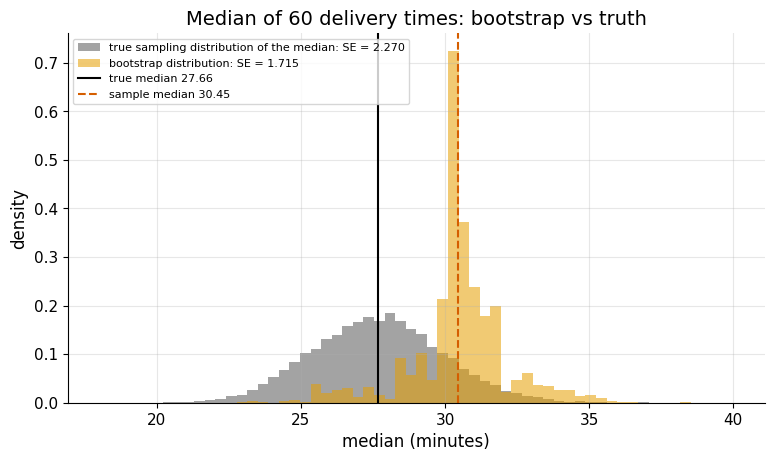

In [5]:
true_medians = np.array([np.median(population[rng.choice(N, n, replace=False)]) for _ in range(20_000)])
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(true_medians, bins=60, density=True, range=(18, 40), color=NEUTRAL, alpha=0.6, label=f"true sampling distribution of the median: SE = {true_medians.std():.3f}")
ax.hist(boot_medians, bins=60, density=True, range=(18, 40), color=SIM, alpha=0.55, label=f"bootstrap distribution: SE = {boot_medians.std(ddof=1):.3f}")
ax.axvline(np.median(population), color="black", label=f"true median {np.median(population):.2f}")
ax.axvline(np.median(sample), color=HIGHLIGHT, linestyle="--", label=f"sample median {np.median(sample):.2f}")
ax.set_title("Median of 60 delivery times: bootstrap vs truth")
ax.set_xlabel("median (minutes)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.show()

### 7.5 How many resamples? The Monte Carlo error of the bootstrap itself
For B from 10 to 100,000 we recompute the bootstrap SE and the 95 % percentile limits for the *same* sample. They wobble for small B and settle for large B; the SE needs far fewer resamples than the tail limits.

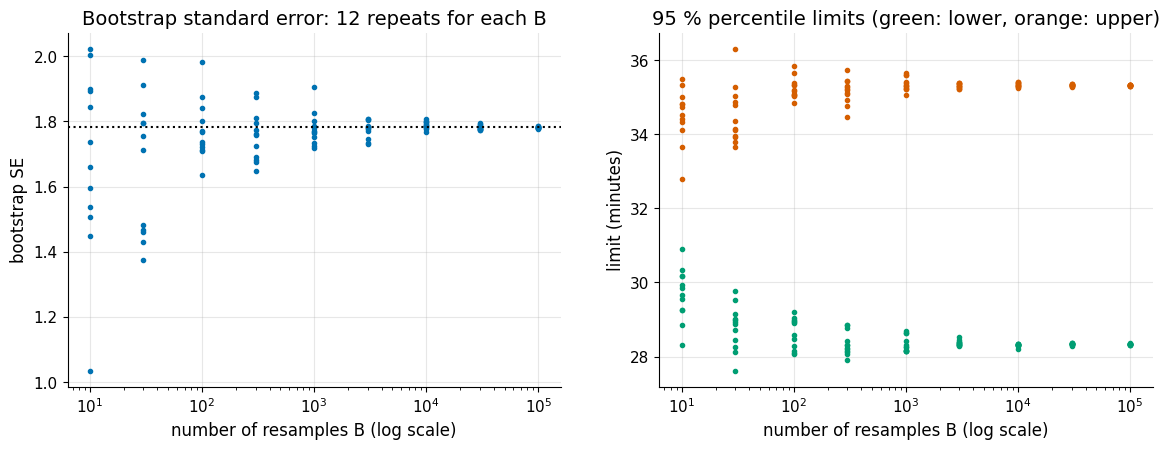

relative spread of the SE estimate (sd / mean over 12 repeats): {10: 0.1606, 30: 0.1212, 100: 0.0494, 300: 0.0421, 1000: 0.0274, 3000: 0.0144, 10000: 0.0061, 30000: 0.0041, 100000: 0.0016}
theory 1 / sqrt(2 B): {10: 0.2236, 30: 0.1291, 100: 0.0707, 300: 0.0408, 1000: 0.0224, 3000: 0.0129, 10000: 0.0071, 30000: 0.0041, 100000: 0.0022}


In [6]:
Bs = np.array([10, 30, 100, 300, 1000, 3000, 10_000, 30_000, 100_000])
se_est, lo_est, hi_est = [], [], []
check_rng = np.random.default_rng(11)
for b in Bs:
    reps = []
    for _ in range(12):
        m = sample[check_rng.integers(0, n, (b, n))].mean(axis=1) if b <= 10_000 else np.concatenate([sample[check_rng.integers(0, n, (10_000, n))].mean(axis=1) for _ in range(b // 10_000)])
        reps.append((m.std(ddof=1), np.percentile(m, 2.5), np.percentile(m, 97.5)))
    reps = np.array(reps)
    se_est.append(reps[:, 0]); lo_est.append(reps[:, 1]); hi_est.append(reps[:, 2])
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.6))
for b, v in zip(Bs, se_est):
    ax_a.plot(np.full(v.size, b), v, ".", color=MAIN)
ax_a.axhline(np.mean(se_est[-1]), color="black", linestyle=":")
ax_a.set_xscale("log"); ax_a.set_title("Bootstrap standard error: 12 repeats for each B")
ax_a.set_xlabel("number of resamples B (log scale)"); ax_a.set_ylabel("bootstrap SE")
for b, lo, hi in zip(Bs, lo_est, hi_est):
    ax_b.plot(np.full(lo.size, b), lo, ".", color=COLORS[2]); ax_b.plot(np.full(hi.size, b), hi, ".", color=HIGHLIGHT)
ax_b.set_xscale("log"); ax_b.set_title("95 % percentile limits (green: lower, orange: upper)")
ax_b.set_xlabel("number of resamples B (log scale)"); ax_b.set_ylabel("limit (minutes)")
plt.show()
print("relative spread of the SE estimate (sd / mean over 12 repeats):", {int(b): round(float(v.std() / v.mean()), 4) for b, v in zip(Bs, se_est)})
print("theory 1 / sqrt(2 B):", {int(b): round(float(1 / np.sqrt(2 * b)), 4) for b in Bs})

### 7.6 When the bootstrap fails: the sample maximum
For Uniform$(0,\theta)$ data the sample maximum has a smooth sampling distribution just below $\theta$. The bootstrap of the maximum has a **large spike at the sample maximum** (about 63 % of resamples contain it), so it misrepresents the sampling distribution.

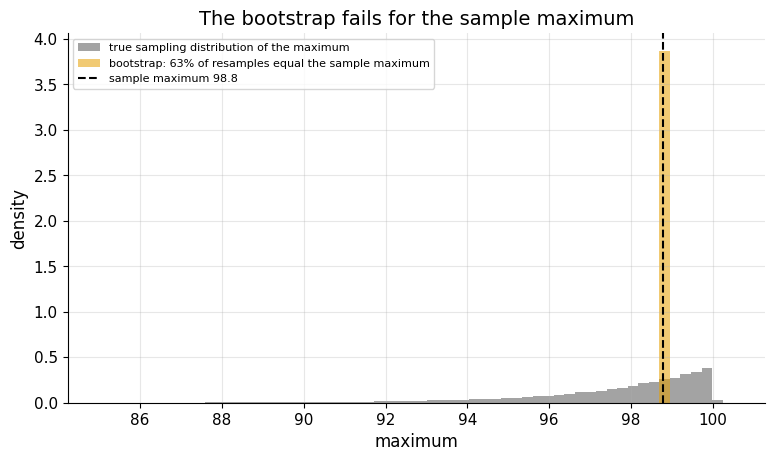

share of bootstrap resamples whose maximum equals the sample maximum: 0.635; theory 1 - (1 - 1/n)^n = 0.637


In [7]:
theta, n_small = 100.0, 40
data = rng.uniform(0, theta, n_small)
true_max = rng.uniform(0, theta, (30_000, n_small)).max(axis=1)
boot_max = data[rng.integers(0, n_small, (30_000, n_small))].max(axis=1)
share_equal = np.mean(boot_max == data.max())
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(true_max, bins=60, range=(85, 100.5), density=True, color=NEUTRAL, alpha=0.6, label="true sampling distribution of the maximum")
ax.hist(boot_max, bins=60, range=(85, 100.5), density=True, color=SIM, alpha=0.55, label=f"bootstrap: {share_equal:.0%} of resamples equal the sample maximum")
ax.axvline(data.max(), color="black", linestyle="--", label=f"sample maximum {data.max():.1f}")
ax.set_title("The bootstrap fails for the sample maximum")
ax.set_xlabel("maximum"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.show()
print(f"share of bootstrap resamples whose maximum equals the sample maximum: {share_equal:.3f}; theory 1 - (1 - 1/n)^n = {1 - (1 - 1 / n_small) ** n_small:.3f}")
assert abs(share_equal - (1 - (1 - 1 / n_small) ** n_small)) < 0.01

## 8. 3D visuals

### 8.1 Static: the joint bootstrap distribution of the mean and the median
Each bootstrap resample gives a (mean, median) pair. The surface is the joint density of those pairs from 40,000 resamples of the sample of 60: a tilted ridge, because mean and median move together but not perfectly.

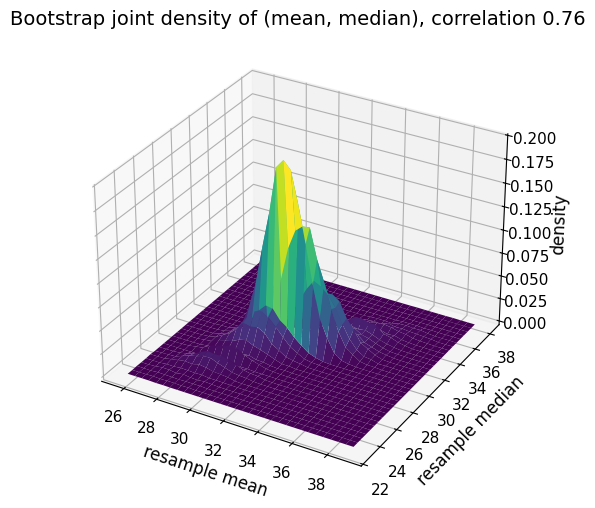

In [8]:
big_idx = rng.integers(0, n, (40_000, n))
bm, bmed = sample[big_idx].mean(axis=1), np.median(sample[big_idx], axis=1)
H, xe, ye = np.histogram2d(bm, bmed, bins=32, density=True)
X, Y = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2, indexing="ij")
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, H, cmap="viridis", edgecolor="none")
ax.set_title(f"Bootstrap joint density of (mean, median), correlation {np.corrcoef(bm, bmed)[0, 1]:.2f}")
ax.set_xlabel("resample mean"); ax.set_ylabel("resample median"); ax.set_zlabel("density")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the Monte Carlo standard error over (p, B)
$\mathrm{SE}=\sqrt{p(1-p)/B}$ for a simulated probability. It is largest at $p=0.5$ and shrinks only with the square root of the number of simulations: halving it costs four times the runs.

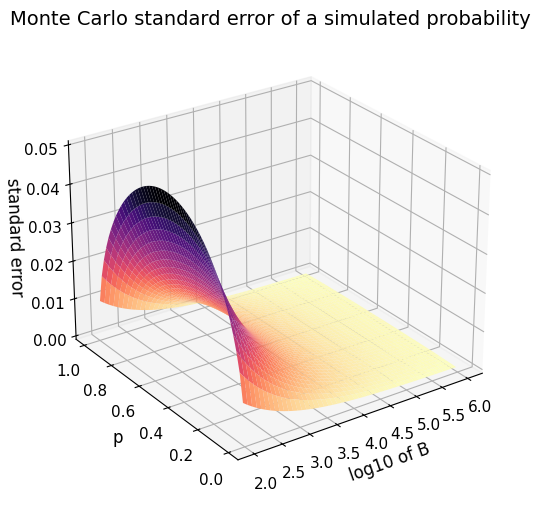

In [9]:
p_axis = np.linspace(0.01, 0.99, 50)
B_axis = np.logspace(2, 6, 50)
SE = np.sqrt(p_axis[:, None] * (1 - p_axis[:, None]) / B_axis[None, :])
Bg, Pg = np.meshgrid(np.log10(B_axis), p_axis)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Bg, Pg, SE, cmap="magma_r", edgecolor="none")
ax.set_title("Monte Carlo standard error of a simulated probability")
ax.set_xlabel("log10 of B"); ax.set_ylabel("p"); ax.set_zlabel("standard error")
ax.view_init(elev=26, azim=-125)
plt.show()

### 8.3 Interactive Plotly version of 8.2
Hover to read the standard error for any (p, B).

In [10]:
fig = go.Figure(go.Surface(x=B_axis, y=p_axis, z=SE, colorscale="Magma", reversescale=True))
fig.update_layout(title="Monte Carlo SE = sqrt(p (1 - p) / B)", width=750, height=550,
                  scene=dict(xaxis_title="B (simulations)", yaxis_title="p", zaxis_title="standard error", xaxis_type="log"))
fig.show()

## 9. Simulation vs theory

### 9.1 The bootstrap SE of the mean equals sqrt((n-1)/n) s / sqrt(n)
With many resamples the bootstrap SE of the mean must match this exact value (5.2); we check it on ten different samples.

In [11]:
rows = []
for seed in range(10):
    g = np.random.default_rng(100 + seed)
    smp = population[g.choice(N, 60, replace=False)]
    bs = smp[g.integers(0, 60, (20_000, 60))].mean(axis=1).std(ddof=1)
    exact = np.sqrt(59 / 60) * smp.std(ddof=1) / np.sqrt(60)
    rows.append({"sample": seed, "bootstrap SE (B = 20,000)": bs, "sqrt((n-1)/n) s / sqrt(n)": exact, "textbook s / sqrt(n)": smp.std(ddof=1) / np.sqrt(60)})
check = pd.DataFrame(rows)
print(check.round(4).to_string(index=False))
assert np.allclose(check["bootstrap SE (B = 20,000)"], check["sqrt((n-1)/n) s / sqrt(n)"], rtol=0.02)

 sample  bootstrap SE (B = 20,000)  sqrt((n-1)/n) s / sqrt(n)  textbook s / sqrt(n)
      0                     1.9076                     1.9025                1.9186
      1                     2.0013                     2.0057                2.0227
      2                     1.5839                     1.5882                1.6016
      3                     1.9582                     1.9665                1.9831
      4                     2.2159                     2.2047                2.2233
      5                     1.8950                     1.8993                1.9153
      6                     2.2053                     2.2073                2.2260
      7                     1.8459                     1.8474                1.8630
      8                     2.6614                     2.6511                2.6734
      9                     1.5661                     1.5723                1.5856


### 9.2 Is the bootstrap SE of the median close to the true SE?
Over 300 different samples, the bootstrap SE of the median (B = 1,000) against the true SE from 20,000 fresh samples. The bootstrap SE is noisy for a single sample but right on average.

true SE of the median 2.270; bootstrap SE estimates: mean 2.314, sd across samples 0.539, 5th to 95th percentile 1.483 to 3.341


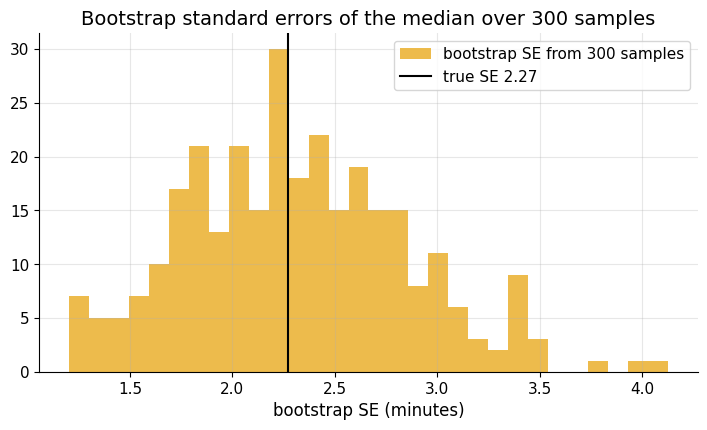

In [12]:
true_se_median = true_medians.std()
estimates = []
for _ in range(300):
    smp = population[rng.choice(N, 60, replace=False)]
    estimates.append(np.median(smp[rng.integers(0, 60, (1000, 60))], axis=1).std(ddof=1))
estimates = np.array(estimates)
print(f"true SE of the median {true_se_median:.3f}; bootstrap SE estimates: mean {estimates.mean():.3f}, sd across samples {estimates.std():.3f}, 5th to 95th percentile {np.percentile(estimates, 5):.3f} to {np.percentile(estimates, 95):.3f}")
assert abs(estimates.mean() / true_se_median - 1) < 0.2
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.hist(estimates, bins=30, color=SIM, alpha=0.7, label="bootstrap SE from 300 samples")
ax.axvline(true_se_median, color="black", label=f"true SE {true_se_median:.2f}")
ax.set_title("Bootstrap standard errors of the median over 300 samples")
ax.set_xlabel("bootstrap SE (minutes)"); ax.legend()
plt.show()

### 9.3 Monte Carlo error: simulation against sqrt(p(1-p)/B)
We estimate a probability (P(Normal > 1) = 0.1587) with B = 1,000, 10,000 and 100,000 runs, 2,000 times each: the spread of the estimates is the Monte Carlo standard error.

In [13]:
p_true = stats.norm.sf(1.0)
rows = []
for B in (1000, 10_000, 100_000):
    est = rng.binomial(B, p_true, 2000) / B                       # each value is the share of B simulated Normals above 1
    rows.append({"B": B, "sd of estimates": est.std(), "theory sqrt(p(1-p)/B)": np.sqrt(p_true * (1 - p_true) / B), "mean estimate": est.mean()})
mc = pd.DataFrame(rows)
print(mc.round(5).to_string(index=False))
assert np.allclose(mc["sd of estimates"], mc["theory sqrt(p(1-p)/B)"], rtol=0.06)

     B  sd of estimates  theory sqrt(p(1-p)/B)  mean estimate
  1000          0.01169                0.01155        0.15912
 10000          0.00368                0.00365        0.15870
100000          0.00112                0.00116        0.15865


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [14]:
res = stats.bootstrap((sample,), np.median, n_resamples=9999, confidence_level=0.95, method="percentile", random_state=1)
print("scipy percentile bootstrap CI for the median:", np.round([res.confidence_interval.low, res.confidence_interval.high], 3), "| bootstrap SE:", round(res.standard_error, 3))
res_bca = stats.bootstrap((sample,), np.median, n_resamples=9999, confidence_level=0.95, method="BCa", random_state=1)
print("BCa interval:", np.round([res_bca.confidence_interval.low, res_bca.confidence_interval.high], 3))
print("by hand with NumPy: resample indices rng.integers(0, n, (B, n)), then np.percentile(stat, [2.5, 97.5]):", np.round(np.percentile(boot_medians, [2.5, 97.5]), 3))
print("permutation test for a difference of means (scipy.stats.permutation_test), p-value:",
      round(stats.permutation_test((sample[:30], sample[30:]), lambda a, b: a.mean() - b.mean(), n_resamples=5000, random_state=1).pvalue, 3))
print("one resample draws with replacement: np.random.default_rng(0).choice([1, 2, 3, 4, 5], size=5, replace=True) ->", np.random.default_rng(0).choice([1, 2, 3, 4, 5], size=5, replace=True))

scipy percentile bootstrap CI for the median: [26.023 34.218] | bootstrap SE: 1.672
BCa interval: [25.982 34.218]
by hand with NumPy: resample indices rng.integers(0, n, (B, n)), then np.percentile(stat, [2.5, 97.5]): [25.803 34.218]
permutation test for a difference of means (scipy.stats.permutation_test), p-value: 0.192
one resample draws with replacement: np.random.default_rng(0).choice([1, 2, 3, 4, 5], size=5, replace=True) -> [5 4 3 2 2]


## 11. Real-world worked examples

---
### Example 1 (main): a confidence interval for the median delivery time

**Scenario.** The courier company of 05_03 timed **$n=60$** randomly chosen deliveries (the sample of Section 7.2: mean $\approx30$ minutes, right-skewed). Management quotes the **median** ("half of deliveries take less than this") because it is robust to the few very long deliveries. There is no simple formula for the standard error of a median.

**Questions**
1. What is the sample median and its **bootstrap standard error**?
2. Give a **95 % confidence interval** for the true median (percentile, basic and BCa).
3. How does the interval's **coverage** hold up over many repeated samples (we know the truth here)?
4. How many resamples $B$ do we need?

### 11.1 By hand
**The procedure on a toy sample.** Take five delivery times $\{12, 18, 25, 31, 44\}$ (median 25). One bootstrap resample draws five values *with replacement*, e.g. $\{18, 18, 44, 25, 12\}$ (median 18); another, $\{31, 31, 25, 12, 31\}$ (median 31); another, $\{44, 25, 25, 18, 25\}$ (median 25). Repeating $B$ times gives a list of medians; its standard deviation is the bootstrap SE and its 2.5 % and 97.5 % quantiles are the percentile interval.

**Q1 and Q2 on the real sample** are exactly this recipe with $n=60$ and $B=10{,}000$; the arithmetic is too long to do by hand, which is the point of the bootstrap. We *can* check one thing by hand: for the **mean** the ideal bootstrap SE is $\sqrt{59/60}\,s/\sqrt{60}$, which we compare with the simulated value as a sanity check on the code.

**Q4.** For the SE, relative error $\approx1/\sqrt{2B}$: $B=1{,}000$ gives about 2 %. For the interval limits, take $B\ge5{,}000$.

In [15]:
sample_median = np.median(sample)
B = 10_000
code_rng = np.random.default_rng(21)
medians = np.median(sample[code_rng.integers(0, n, (B, n))], axis=1)
boot_se = medians.std(ddof=1)
percentile_ci = np.percentile(medians, [2.5, 97.5])
basic_ci = (2 * sample_median - percentile_ci[1], 2 * sample_median - percentile_ci[0])
print(f"Q1: sample median {sample_median:.3f}, bootstrap SE {boot_se:.3f}, bootstrap bias {medians.mean() - sample_median:+.3f}")
res_bca = stats.bootstrap((sample,), np.median, n_resamples=9999, confidence_level=0.95, method="BCa", random_state=3)
print(f"Q2: percentile {percentile_ci.round(2)}, basic {np.round(basic_ci, 2)}, BCa {np.round([res_bca.confidence_interval.low, res_bca.confidence_interval.high], 2)}")
print(f"    truth: population median = {np.median(population):.3f}")
# sanity check of the code on the mean (5.2): ideal bootstrap SE = sqrt((n-1)/n) s / sqrt(n)
means_check = sample[code_rng.integers(0, n, (B, n))].mean(axis=1)
print(f"sanity check: bootstrap SE of the mean {means_check.std(ddof=1):.4f} vs sqrt((n-1)/n) s / sqrt(n) = {np.sqrt((n - 1) / n) * sample.std(ddof=1) / np.sqrt(n):.4f}")

Q1: sample median 30.449, bootstrap SE 1.718, bootstrap bias +0.053
Q2: percentile [25.8  34.22], basic [26.68 35.09], BCa [25.8  34.22]
    truth: population median = 27.657
sanity check: bootstrap SE of the mean 1.7865 vs sqrt((n-1)/n) s / sqrt(n) = 1.7826


### 11.2 In code with `scipy`, and the asserts

In [16]:
res = stats.bootstrap((sample,), np.median, n_resamples=9999, confidence_level=0.95, method="percentile", random_state=4)
assert abs(res.standard_error - boot_se) < 0.1 * boot_se                      # our hand-rolled SE agrees with scipy's
assert abs(res.confidence_interval.low - percentile_ci[0]) < 0.6 and abs(res.confidence_interval.high - percentile_ci[1]) < 0.6
assert abs(means_check.std(ddof=1) - np.sqrt((n - 1) / n) * sample.std(ddof=1) / np.sqrt(n)) < 0.01
print("scipy percentile interval:", np.round([res.confidence_interval.low, res.confidence_interval.high], 3), "| standard error:", round(res.standard_error, 3))
print("Resamples needed (Q4): relative error of the SE with B = 10,000:", round(1 / np.sqrt(2 * 10_000), 4), "; with B = 1,000:", round(1 / np.sqrt(2 * 1000), 4))

scipy percentile interval: [25.803 34.218] | standard error: 1.724
Resamples needed (Q4): relative error of the SE with B = 10,000: 0.0071 ; with B = 1,000: 0.0224


### 11.3 Verify by simulation: the coverage of the interval
We know the true median of the population. Draw 600 new samples of 60, build each interval with B = 1,000 resamples, and count how often it contains the true median.

In [17]:
true_median = np.median(population)
cover_rng = np.random.default_rng(31)
hits = {"percentile": 0, "basic": 0, "normal (boot SE)": 0}
widths = []
reps = 600
for _ in range(reps):
    smp = population[cover_rng.choice(N, n, replace=False)]
    m = np.median(smp[cover_rng.integers(0, n, (1000, n))], axis=1)
    med, se = np.median(smp), m.std(ddof=1)
    lo, hi = np.percentile(m, [2.5, 97.5])
    hits["percentile"] += lo <= true_median <= hi
    hits["basic"] += 2 * med - hi <= true_median <= 2 * med - lo
    hits["normal (boot SE)"] += abs(med - true_median) <= 1.96 * se
    widths.append(hi - lo)
coverage = {k: v / reps for k, v in hits.items()}
print("coverage of the 95 % intervals over", reps, "samples:", {k: round(v, 3) for k, v in coverage.items()}, "| average width", round(float(np.mean(widths)), 2))
assert 0.92 <= coverage['percentile'] <= 0.98 and 0.91 <= coverage['normal (boot SE)'] <= 0.98      # the basic interval is expected to under-cover here (see the interpretation)

coverage of the 95 % intervals over 600 samples: {'percentile': np.float64(0.95), 'basic': np.float64(0.862), 'normal (boot SE)': np.float64(0.942)} | average width 9.04


### 11.4 Plots with the regions shaded

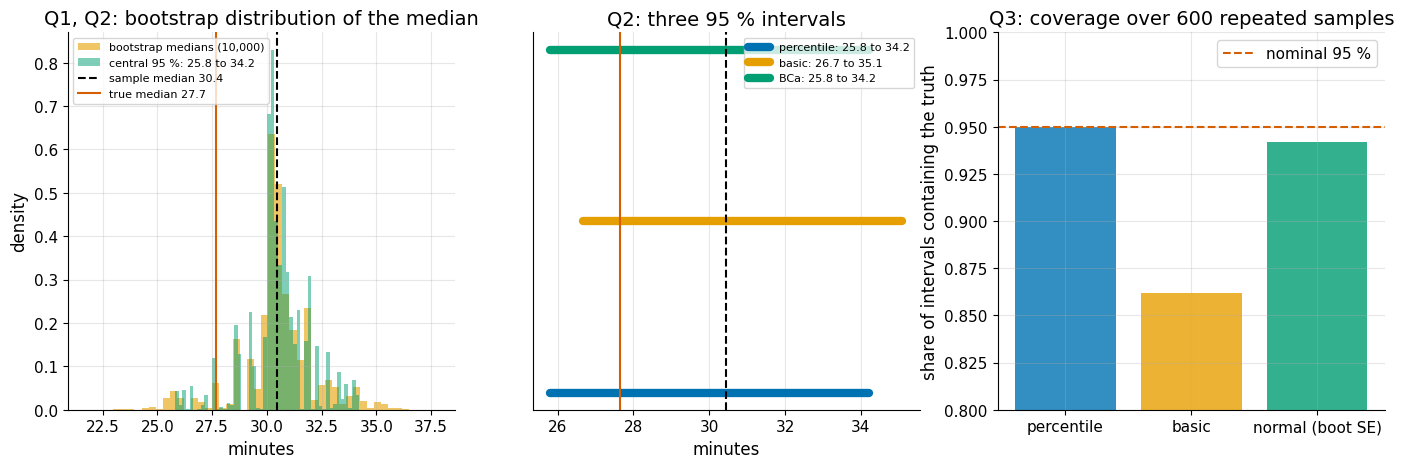

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
axes[0].hist(medians, bins=50, density=True, color=SIM, alpha=0.6, label="bootstrap medians (10,000)")
xs = np.linspace(medians.min(), medians.max(), 200)
inside = (medians >= percentile_ci[0]) & (medians <= percentile_ci[1])
axes[0].hist(medians[inside], bins=50, density=True, color=COLORS[2], alpha=0.5, label=f"central 95 %: {percentile_ci[0]:.1f} to {percentile_ci[1]:.1f}")
axes[0].axvline(sample_median, color="black", linestyle="--", label=f"sample median {sample_median:.1f}")
axes[0].axvline(true_median, color=HIGHLIGHT, label=f"true median {true_median:.1f}")
axes[0].set_title("Q1, Q2: bootstrap distribution of the median")
axes[0].set_xlabel("minutes"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
for y, (name, (lo_, hi_), color) in enumerate([("percentile", percentile_ci, MAIN), ("basic", basic_ci, COLORS[1]), ("BCa", (res_bca.confidence_interval.low, res_bca.confidence_interval.high), COLORS[2])]):
    axes[1].plot([lo_, hi_], [y, y], color=color, linewidth=6, solid_capstyle="round", label=f"{name}: {lo_:.1f} to {hi_:.1f}")
axes[1].axvline(sample_median, color="black", linestyle="--")
axes[1].axvline(true_median, color=HIGHLIGHT)
axes[1].set_yticks([]); axes[1].set_title("Q2: three 95 % intervals"); axes[1].set_xlabel("minutes"); axes[1].legend(fontsize=8, loc="upper right")
axes[2].bar(list(coverage), list(coverage.values()), color=[MAIN, COLORS[1], COLORS[2]], alpha=0.8)
axes[2].axhline(0.95, color=HIGHLIGHT, linestyle="--", label="nominal 95 %")
axes[2].set_ylim(0.8, 1.0)
axes[2].set_title("Q3: coverage over 600 repeated samples")
axes[2].set_ylabel("share of intervals containing the truth"); axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
See the printed numbers above. In words:
- The sample median is **30.4 minutes** with a bootstrap standard error of about **1.7 minutes** (bias +0.05, negligible). A single sample's bootstrap SE is itself noisy: over 300 samples (9.2) the bootstrap SE ranged from 1.5 to 3.3 around the true SE of 2.27, so do not read it to two decimals.
- The 95 % **percentile interval is 25.8 to 34.2 minutes**; BCa gives the same limits and the basic interval is shifted up (26.7 to 35.1). All of them contain the true population median (27.7 minutes) in this sample.
- **Coverage over 600 repeated samples:** the percentile interval covers **95.0 %** of the time and the Normal interval (median plus or minus 1.96 bootstrap SEs) **94.2 %**: both honour their promise. The **basic interval covers only 86.2 %**: flipping the quantiles overcorrects for a skewed, discrete-looking statistic like the median of 60 observations. This is why one checks coverage by simulation instead of trusting a recipe.
- $B=10{,}000$ resamples is more than enough; $B=1{,}000$ already pins the SE to about 2 %.
- **Decision:** report "the median delivery time is about 30 minutes (95 % interval 26 to 34)". Do not quote the median to the minute: the data cannot distinguish 27 from 33. To halve the interval width the company would need about four times as many timed deliveries.

---
### Example 2: an A/B test with a relative lift (bootstrap and permutation)

**Scenario (illustrative).** Version A: **48 purchases out of 400 visitors** (12.0 %). Version B: **66 out of 420** (15.7 %). The relative lift $(\hat p_B-\hat p_A)/\hat p_A$ is about 31 %. The standard error of a *ratio* is awkward; the bootstrap handles it. Is the lift distinguishable from zero?

**By hand.** The difference of proportions is $0.157-0.120=0.037$ with SE $\sqrt{0.12\cdot0.88/400+0.157\cdot0.843/420}=0.0242$, so about 1.5 standard errors (not conclusive). The bootstrap resamples visitors within each group and recomputes the lift.

In [19]:
a_success, a_n, b_success, b_n = 48, 400, 66, 420
visitors_a = np.r_[np.ones(a_success), np.zeros(a_n - a_success)]
visitors_b = np.r_[np.ones(b_success), np.zeros(b_n - b_success)]
pa, pb = visitors_a.mean(), visitors_b.mean()
diff = pb - pa
se_diff = np.sqrt(pa * (1 - pa) / a_n + pb * (1 - pb) / b_n)
print(f"rates: A {pa:.4f}, B {pb:.4f}; difference {diff:.4f}, SE {se_diff:.4f}, z = {diff / se_diff:.3f}; relative lift {diff / pa:.3f}")
ab_rng = np.random.default_rng(41)
B = 20_000
ba = ab_rng.binomial(a_n, pa, B) / a_n                       # resampling visitors with replacement within a group is the same as a Binomial draw
bb = ab_rng.binomial(b_n, pb, B) / b_n
boot_diff, boot_lift = bb - ba, (bb - ba) / ba
print(f"bootstrap SE of the difference {boot_diff.std(ddof=1):.4f} (formula {se_diff:.4f}); 95 % percentile interval for the difference: {np.percentile(boot_diff, [2.5, 97.5]).round(4)}")
print(f"95 % percentile interval for the relative lift: {np.percentile(boot_lift, [2.5, 97.5]).round(3)} ; bootstrap SE of the lift {boot_lift.std(ddof=1):.3f}")
assert abs(boot_diff.std(ddof=1) / se_diff - 1) < 0.03
# permutation test: shuffle the group labels (the null: A and B are the same)
everything = np.r_[visitors_a, visitors_b]
perm_diff = np.empty(20_000)
for i in range(20_000):
    ab_rng.shuffle(everything)
    perm_diff[i] = everything[a_n:].mean() - everything[:a_n].mean()
p_perm = np.mean(np.abs(perm_diff) >= abs(diff))
print(f"permutation test: two-sided p-value {p_perm:.4f}; normal-theory pooled z-test p-value {2 * stats.norm.sf(abs(diff) / np.sqrt(((a_success + b_success) / (a_n + b_n)) * (1 - (a_success + b_success) / (a_n + b_n)) * (1 / a_n + 1 / b_n))):.4f}")

rates: A 0.1200, B 0.1571; difference 0.0371, SE 0.0241, z = 1.543; relative lift 0.310
bootstrap SE of the difference 0.0239 (formula 0.0241); 95 % percentile interval for the difference: [-0.0093  0.0838]
95 % percentile interval for the relative lift: [-0.065  0.859] ; bootstrap SE of the lift 0.241


permutation test: two-sided p-value 0.1295; normal-theory pooled z-test p-value 0.1244


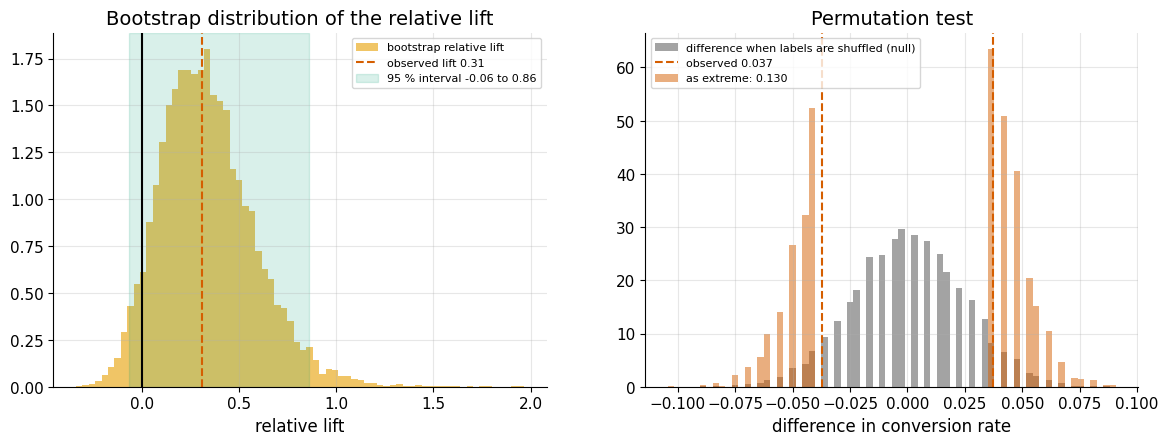

In [20]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.6))
ci = np.percentile(boot_lift, [2.5, 97.5])
ax_a.hist(boot_lift, bins=70, density=True, color=SIM, alpha=0.6, label="bootstrap relative lift")
ax_a.axvline(0, color="black"); ax_a.axvline(diff / pa, color=HIGHLIGHT, linestyle="--", label=f"observed lift {diff / pa:.2f}")
x = np.linspace(boot_lift.min(), boot_lift.max(), 300)
ax_a.axvspan(ci[0], ci[1], color=COLORS[2], alpha=0.15, label=f"95 % interval {ci[0]:.2f} to {ci[1]:.2f}")
ax_a.set_title("Bootstrap distribution of the relative lift"); ax_a.set_xlabel("relative lift"); ax_a.legend(fontsize=8)
ax_b.hist(perm_diff, bins=70, density=True, color=NEUTRAL, alpha=0.6, label="difference when labels are shuffled (null)")
ax_b.axvline(diff, color=HIGHLIGHT, linestyle="--", label=f"observed {diff:.3f}"); ax_b.axvline(-diff, color=HIGHLIGHT, linestyle="--")
tail = np.abs(perm_diff) >= abs(diff)
ax_b.hist(perm_diff[tail], bins=70, range=(perm_diff.min(), perm_diff.max()), density=True, color=HIGHLIGHT, alpha=0.5, label=f"as extreme: {tail.mean():.3f}")
ax_b.set_title("Permutation test"); ax_b.set_xlabel("difference in conversion rate"); ax_b.legend(fontsize=8)
plt.show()

**Interpretation.** The relative lift is about **+31 %**, but the bootstrap interval for it is wide (printed above; it reaches below zero or very close to it): with fewer than 500 visitors per version the data are consistent with *no improvement* (the interval starts at about -7 %) and with an improvement of 86 %. The bootstrap standard error of the difference matches the textbook formula (0.024), and the permutation p-value (0.13) agrees with the classical pooled z-test (0.12). **Decision:** do not declare a winner; to detect a 3.7-point difference reliably you would need roughly 2,000 visitors per version (Module 06 covers the power calculation). Note how the bootstrap gave the interval of a *ratio* with no formula at all.

---
### Example 3: Monte Carlo for a project deadline

**Scenario (illustrative).** A project has five sequential tasks with uncertain durations (days): **design** Triangular(5, 8, 14); **build** Lognormal with mean 20 and SD 7; **test** Uniform(6, 12); **fix** Gamma(shape 2, scale 3); **deploy** 1 + Exponential(mean 3). The deadline is **65 days**. What is the probability that the project is **late**, and which 90 % completion date should be promised? Adding five different distributions has no closed form: simulate.

**By hand (what we can do).** The means are 9, 20, 9, 6 and 4, so the total mean is **48 days**; the variances are 3.5, 49, 3, 18 and 9, so the total variance is **82.5** (SD 9.08). A rough CLT answer: $P(\text{total}>65)\approx1-\Phi\big(\frac{65-48}{9.08}\big)=1-\Phi(1.87)=0.031$. Monte Carlo will tell us how good this is.

In [21]:
mc_rng = np.random.default_rng(51)
def project_durations(size, generator):
    s_build = np.sqrt(np.log(1 + (7 / 20) ** 2)); m_build = np.log(20) - s_build**2 / 2
    return (generator.triangular(5, 8, 14, size) + generator.lognormal(m_build, s_build, size) + generator.uniform(6, 12, size)
            + generator.gamma(2, 3, size) + 1 + generator.exponential(3, size))

B = 2_000_000
total = project_durations(B, mc_rng)
p_late = np.mean(total > 65)
se_late = np.sqrt(p_late * (1 - p_late) / B)
print(f"mean {total.mean():.3f} (theory 48), sd {total.std():.3f} (theory {np.sqrt(82.5):.3f})")
print(f"P(late) = {p_late:.5f} +/- {1.96 * se_late:.5f} (95 % Monte Carlo error); CLT estimate {stats.norm.sf(65, 48, np.sqrt(82.5)):.5f}")
print(f"90th, 95th, 99th percentiles of the duration: {np.percentile(total, [90, 95, 99]).round(1)}; skewness {stats.skew(total):.3f}")
b_needed = int(np.ceil(1.96**2 * p_late * (1 - p_late) / 0.001**2))
print(f"simulations needed to know P(late) to within +/- 0.001: {b_needed:,}")
assert abs(total.mean() - 48) < 0.05 and abs(total.std() - np.sqrt(82.5)) < 0.05

mean 47.998 (theory 48), sd 9.081 (theory 9.083)
P(late) = 0.04537 +/- 0.00029 (95 % Monte Carlo error); CLT estimate 0.03063
90th, 95th, 99th percentiles of the duration: [59.9 64.4 73.8]; skewness 0.716
simulations needed to know P(late) to within +/- 0.001: 166,404


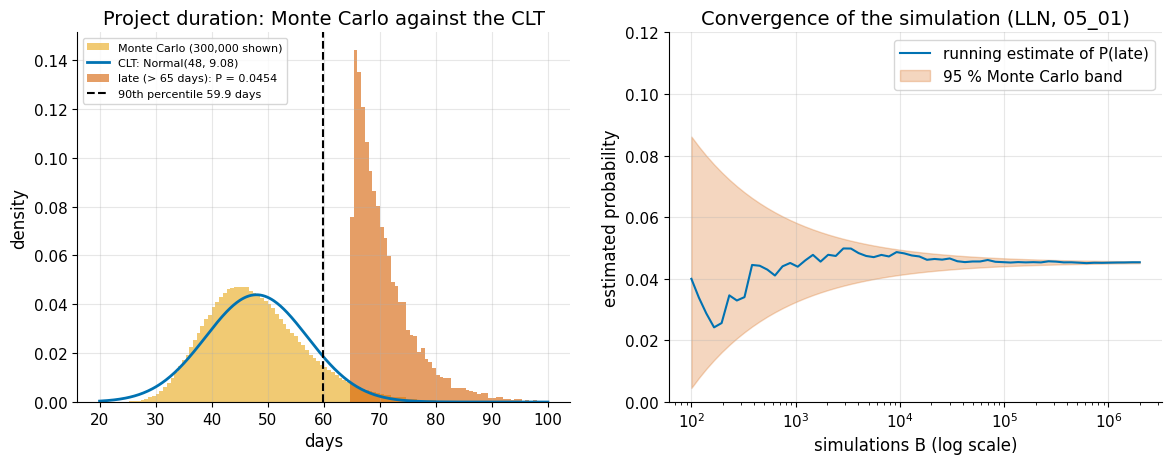

In [22]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.linspace(20, 100, 400)
ax_a.hist(total[:300_000], bins=120, range=(20, 100), density=True, color=SIM, alpha=0.55, label="Monte Carlo (300,000 shown)")
ax_a.plot(x, stats.norm(48, np.sqrt(82.5)).pdf(x), color=MAIN, linewidth=2, label="CLT: Normal(48, 9.08)")
sub = total[:300_000]
ax_a.hist(sub[sub > 65], bins=120, range=(20, 100), density=True, color=HIGHLIGHT, alpha=0.6, weights=np.full((sub > 65).sum(), (sub > 65).mean()) / (sub > 65).sum() * 1.0, label=f"late (> 65 days): P = {p_late:.4f}")
ax_a.axvline(np.percentile(total, 90), color="black", linestyle="--", label=f"90th percentile {np.percentile(total, 90):.1f} days")
ax_a.set_title("Project duration: Monte Carlo against the CLT")
ax_a.set_xlabel("days"); ax_a.set_ylabel("density"); ax_a.legend(fontsize=8)
Bs = np.logspace(2, 6.3, 60).astype(int)
running = np.cumsum(total[:int(Bs[-1])] > 65) / np.arange(1, int(Bs[-1]) + 1)
ax_b.plot(Bs, running[Bs - 1], color=MAIN, label="running estimate of P(late)")
ax_b.fill_between(Bs, p_late - 1.96 * np.sqrt(p_late * (1 - p_late) / Bs), p_late + 1.96 * np.sqrt(p_late * (1 - p_late) / Bs), color=HIGHLIGHT, alpha=0.25, label="95 % Monte Carlo band")
ax_b.set_xscale("log"); ax_b.set_ylim(0, 0.12)
ax_b.set_title("Convergence of the simulation (LLN, 05_01)")
ax_b.set_xlabel("simulations B (log scale)"); ax_b.set_ylabel("estimated probability"); ax_b.legend()
plt.show()

**Interpretation.** The simulated probability of finishing after 65 days is **4.5 %**, while the CLT guess says only **3.1 %**: the CLT *underestimates the risk by about a third*, because the total is **right-skewed** (skewness 0.72: the lognormal build task and the exponential tail make late finishes more likely than a Normal would say) and the deadline is far in the tail (05_02: the tails converge last). The Monte Carlo error is small (±0.03 percentage points at $B=2$ million), and about **166,000 runs** are enough to know the probability to ±0.1 percentage point. **Decision:** promise the **90th percentile (about 60 days)**, not the average of 48; the extra 12 days buy a 90 % chance of keeping the promise (the 95th and 99th percentiles are 64 and 74 days). Changing an assumption (a different build distribution, a parallel task) is a one-line change in the simulation, which is why Monte Carlo is the standard tool for project risk, finance and queueing.

## 12. Where it is used

### Statistics
- **Confidence intervals and standard errors** for medians, percentiles, correlations, ratios and regression coefficients when no formula (or a doubtful one) exists; bias estimation.
- **Permutation tests and Monte Carlo p-values**; the **parametric bootstrap** for model checking.

### Data science
- **A/B testing** with relative lifts and revenue per user, metrics with heavy tails, uncertainty bands for forecasts and KPIs.
- **Risk and capacity simulation:** project deadlines, inventory, queues, financial portfolios (Example 3).

### ML and AI
- **Bagging and random forests** train on bootstrap resamples; the 37 % left out give an out-of-bag error estimate.
- **Uncertainty of model metrics** (AUC, accuracy) by bootstrapping the test set; ensemble and bootstrap-based confidence for deep models; Monte Carlo dropout and sampling in Bayesian methods (Module 07).

## 13. Common pitfalls and misconceptions

- **The bootstrap does not create new information:** it cannot fix a small, biased or unrepresentative sample; the interval is only as good as the sample is a miniature of the population.
- **Resample the right unit:** for clustered or time-series data resample clusters or blocks, not individual rows.
- **Too few resamples:** B of 100 is fine for an SE but not for percentile limits.
- **Extremes and tiny samples:** the bootstrap fails for the maximum/minimum and is unreliable for $n$ below about 15 (7.6).
- **Heavy tails:** with infinite variance the bootstrap of the mean is inconsistent (05_01 and 05_02 warnings apply).
- **Percentile intervals are not magic:** for biased or very skewed statistics prefer BCa; check coverage by simulation when the stakes are high.
- **Monte Carlo is not exact:** report the simulation error ($\sqrt{p(1-p)/B}$) next to the estimate and fix the seed for reproducibility.
- **Confusing the two samples:** the bootstrap sample is drawn from the *data*; Monte Carlo is drawn from a *model*.

## 14. Exercises

1. For the sample $\{3, 5, 8, 13, 21\}$ list the $5^5=3{,}125$ equally likely resamples' *means* conceptually; compute the exact bootstrap SE of the mean from the formula $\sqrt{(n-1)/n}\,s/\sqrt n$ and check it by drawing $B=100{,}000$ resamples.
2. Compute a 95 % percentile bootstrap interval for the **90th percentile** of the delivery-time sample (Section 7.2). Why is this interval wider and less reliable than the one for the median?
3. Estimate $P(X+Y>10)$ for $X\sim N(4,2^2)$ and $Y\sim\text{Exponential}(\text{mean }5)$ by Monte Carlo with $B=10^6$; report the value and its 95 % error. How many runs for $\pm0.0005$?
4. Show that a bootstrap resample of size $n$ leaves out about 36.8 % of the original observations; check it by simulation for $n=50$ and $n=1000$.
5. Repeat the failure experiment of 7.6 for the **mean** of the Uniform data: is the bootstrap of the mean accurate? What is the difference?
6. (Harder) For the Example 2 data compute a bootstrap interval for the **odds ratio** and compare it with the Woolf interval $\exp\big(\ln\widehat{OR}\pm1.96\sqrt{1/a+1/b+1/c+1/d}\big)$.

Solutions are at the end.

## 15. Summary table

| Task | Method | Key formula | Caveat |
|---|---|---|---|
| SE of any statistic | bootstrap | sd of T* over B resamples | B of 200 or more |
| Confidence interval | percentile / basic / BCa | quantiles of T* | use BCa for skewed T |
| Mean | bootstrap or formula | sqrt((n-1)/n) s / sqrt(n) | formula is enough |
| p-value with no formula | permutation test | shuffle labels | exchangeability under the null |
| Probability or mean from a known model | Monte Carlo | SE sqrt(p (1 - p) / B) | tails need large B |
| Failure cases | extremes, tiny n, infinite variance, dependence | | block bootstrap, other methods |

## Solutions

In [23]:
x = np.array([3, 5, 8, 13, 21.0]); n_x = x.size
exact_se = np.sqrt((n_x - 1) / n_x) * x.std(ddof=1) / np.sqrt(n_x)
bs = rng.choice(x, (100_000, n_x), replace=True).mean(axis=1)
print("1: exact", round(exact_se, 4), " bootstrap B = 100,000:", round(bs.std(ddof=1), 4))
q90 = np.percentile(sample[rng.integers(0, 60, (10_000, 60))], 90, axis=1)
print("2: bootstrap CI for the 90th percentile:", np.percentile(q90, [2.5, 97.5]).round(2), "(width", round(float(np.diff(np.percentile(q90, [2.5, 97.5]))[0]), 2), ") vs median CI width", round(float(np.diff(percentile_ci)[0]), 2))
B3 = 1_000_000
v = rng.normal(4, 2, B3) + rng.exponential(5, B3)
p3 = np.mean(v > 10)
print("3: P(X + Y > 10) =", round(p3, 5), "+/-", round(1.96 * np.sqrt(p3 * (1 - p3) / B3), 5), "; runs for +/- 0.0005:", int(np.ceil(1.96**2 * p3 * (1 - p3) / 0.0005**2)))
for n_ in (50, 1000):
    left_out = np.mean([len(set(rng.integers(0, n_, n_))) for _ in range(300)]) / n_
    print("4: n =", n_, " share of distinct observations in a resample:", round(left_out, 4), "(theory", round(1 - (1 - 1 / n_) ** n_, 4), ")")
true_mean_se = 100 / np.sqrt(12) / np.sqrt(40)
bm_ = data[rng.integers(0, n_small, (20_000, n_small))].mean(axis=1)
print("5: bootstrap SE of the mean", round(bm_.std(ddof=1), 3), " true SE", round(true_mean_se, 3), "(the mean is smooth, so the bootstrap works)")
ab = visitors_a.mean(), visitors_b.mean()
a_, b_, c_, d_ = b_success, b_n - b_success, a_success, a_n - a_success
or_hat = (a_ * d_) / (b_ * c_)
woolf = np.exp(np.log(or_hat) + np.array([-1, 1]) * 1.96 * np.sqrt(1 / a_ + 1 / b_ + 1 / c_ + 1 / d_))
bo = ab_rng.binomial(b_n, ab[1], 20_000) / b_n
ba = ab_rng.binomial(a_n, ab[0], 20_000) / a_n
boot_or = (bo / (1 - bo)) / (ba / (1 - ba))
print("6: odds ratio", round(or_hat, 3), " Woolf CI", woolf.round(3), " bootstrap percentile CI", np.percentile(boot_or, [2.5, 97.5]).round(3))

1: exact 2.8844  bootstrap B = 100,000: 2.8763
2: bootstrap CI for the 90th percentile: [41.74 60.62] (width 18.88 ) vs median CI width 8.41
3: P(X + Y > 10) = 0.32659 +/- 0.00092 ; runs for +/- 0.0005: 3379512
4: n = 50  share of distinct observations in a resample: 0.6315 (theory 0.6358 )
4: n = 1000  share of distinct observations in a resample: 0.6331 (theory 0.6323 )
5: bootstrap SE of the mean 4.328  true SE 4.564 (the mean is smooth, so the bootstrap works)
6: odds ratio 1.367  Woolf CI [0.916 2.04 ]  bootstrap percentile CI [0.91 2.06]


**1.** The exact (ideal) bootstrap SE is $\sqrt{4/5}\cdot\dfrac{s}{\sqrt5}=2.884$ with $s=7.21$; the simulation with $B=100{,}000$ gives 2.876, within the Monte Carlo error.

**2.** The 90th percentile is determined by a few observations in the right tail, so it jumps a lot between resamples and the sample hardly contains information about the far tail: the interval is much wider than the median's, and the percentile bootstrap tends to under-cover for such extreme quantiles at small $n$.

**3.** $P(X+Y>10)\approx0.327$ with a 95 % Monte Carlo error of about $\pm0.0009$ at $B=10^6$; for $\pm0.0005$ you need about **3.4 million** runs, because the error shrinks only like $1/\sqrt B$.

**4.** A resample contains $1-(1-1/n)^n\to1-e^{-1}=63.2\,\%$ of the distinct original observations, so about 36.8 % are left out (the out-of-bag points of bagging).

**5.** The mean is a smooth statistic, so the bootstrap of the *mean* works well (bootstrap SE close to the true SE) even though the bootstrap of the *maximum* fails: the failure is specific to non-smooth statistics at the edge of the support.

**6.** The odds ratio is 1.37; the Woolf interval is (0.92, 2.04) and the bootstrap percentile interval (0.91, 2.06): almost identical, both skewed to the right and both including 1. The bootstrap needed no formula.